# Import Library

In [1]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Data Load

In [2]:
df = pd.read_csv('../data/raw/supplier_risk_dataset.csv')

df.head()

,Supplier_ID,Financial_Stability_Score,On_Time_Delivery_Rate,Defect_Rate,Geopolitical_Risk_Index,Lead_Time_Days,Alternative_Suppliers_Available,Contract_Length_Months,Environmental_Compliance,Previous_Disruptions,Risk_Level
0,SUP_30248,95.69,100.00,2.59,52,31.0,3.0,17,48.80,2.0,0
1,SUP_23186,78.32,93.90,5.92,18,7.0,0.0,33,45.19,0.0,1
2,SUP_29736,58.98,100.00,0.00,45,51.0,0.0,10,48.01,2.0,1
3,SUP_27251,68.64,61.83,3.32,41,60.0,4.0,11,84.34,0.0,0
4,SUP_25660,98.93,100.00,1.07,41,31.0,3.0,42,64.41,1.0,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27388 entries, 0 to 27387
Data columns (total 11 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Supplier_ID                      27388 non-null  object 
 1   Financial_Stability_Score        26993 non-null  float64
 2   On_Time_Delivery_Rate            27167 non-null  float64
 3   Defect_Rate                      27072 non-null  float64
 4   Geopolitical_Risk_Index          27388 non-null  int64  
 5   Lead_Time_Days                   27153 non-null  float64
 6   Alternative_Suppliers_Available  27125 non-null  float64
 7   Contract_Length_Months           27388 non-null  int64  
 8   Environmental_Compliance         27018 non-null  float64
 9   Previous_Disruptions             27182 non-null  float64
 10  Risk_Level                       27388 non-null  int64  
dtypes: float64(7), int64(3), object(1)
memory usage: 2.3+ MB


In [4]:
df.describe()

,Financial_Stability_Score,On_Time_Delivery_Rate,Defect_Rate,Geopolitical_Risk_Index,Lead_Time_Days,Alternative_Suppliers_Available,Contract_Length_Months,Environmental_Compliance,Previous_Disruptions,Risk_Level
count,26993.000000,27167.000000,27072.000000,27388.000000,27153.000000,27125.000000,27388.000000,27018.000000,27182.000000,27388.000000
mean,68.654452,84.301183,2.161314,37.789287,31.304497,1.840885,24.987732,62.914392,1.039327,0.700088
std,14.516024,9.528272,1.737208,19.580768,17.961977,1.340377,11.484599,17.745451,1.013811,0.458228
min,6.160000,50.000000,0.000000,0.000000,7.000000,0.000000,6.000000,0.000000,0.000000,0.000000
25%,58.690000,77.760000,0.640000,24.000000,17.000000,1.000000,16.000000,50.530000,0.000000,0.000000
50%,68.470000,84.520000,1.980000,37.000000,30.000000,2.000000,25.000000,63.175000,1.000000,1.000000
75%,78.450000,91.420000,3.360000,51.000000,44.000000,3.000000,33.000000,75.307500,2.000000,1.000000
max,100.000000,100.000000,10.000000,100.000000,120.000000,5.000000,60.000000,100.000000,5.000000,1.000000


# EDA

In [5]:
for feature in df.columns[1:-1]:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Boxplot of {feature}')
    plt.show()

<Figure size 1000x600 with 1 Axes>

<Figure size 1000x600 with 1 Axes>

<Figure size 1000x600 with 1 Axes>

<Figure size 1000x600 with 1 Axes>

<Figure size 1000x600 with 1 Axes>

<Figure size 1000x600 with 1 Axes>

<Figure size 1000x600 with 1 Axes>

<Figure size 1000x600 with 1 Axes>

<Figure size 1000x600 with 1 Axes>

**Keputusan outlier:** nilai ekstrem pada boxplot masih dalam rentang wajar (skor 0–100, lead time 7–120 hari, kontrak 6–60 bulan, alternatif supplier 0–5), bukan kesalahan input → **outlier dibiarkan**. Skala fitur yang berbeda ditangani dengan `StandardScaler` di notebook 02.

# Cek Duplikasi Data

In [6]:
print('Total baris     :', len(df))
print('ID unik         :', df['Supplier_ID'].nunique())
print('Duplikat persis :', df.duplicated().sum())

Total baris     : 27388
ID unik         : 24112
Duplikat persis : 2861


In [7]:
df_clean = df.groupby('Supplier_ID', as_index=False).first()

print('Baris setelah dedup:', len(df_clean))
print('ID duplikat tersisa:', df_clean['Supplier_ID'].duplicated().sum())

Baris setelah dedup: 24112
ID duplikat tersisa: 0


# Cek Missing Value

In [8]:
missing_values_percentage = df_clean.isnull().mean() * 100
print("Missing Values Percentage (setelah dedup):\n", missing_values_percentage.round(3))

Missing Values Percentage (setelah dedup):
 Supplier_ID                        0.000
Financial_Stability_Score          1.294
On_Time_Delivery_Rate              0.680
Defect_Rate                        0.983
Geopolitical_Risk_Index            0.000
Lead_Time_Days                     0.767
Alternative_Suppliers_Available    0.900
Contract_Length_Months             0.000
Environmental_Compliance           1.203
Previous_Disruptions               0.659
Risk_Level                         0.000
dtype: float64


**Keputusan missing value:** sisa missing value kecil (<1.5% per kolom) **tidak di-drop** (`dropna()` akan membuang ~7% baris). Imputasi median dilakukan di notebook 02 **setelah train/test split**, agar statistik imputasi hanya dihitung dari data train (mencegah data leakage).

# Distribusi Target

Risk_Level
1    0.7
0    0.3
Name: proportion, dtype: float64


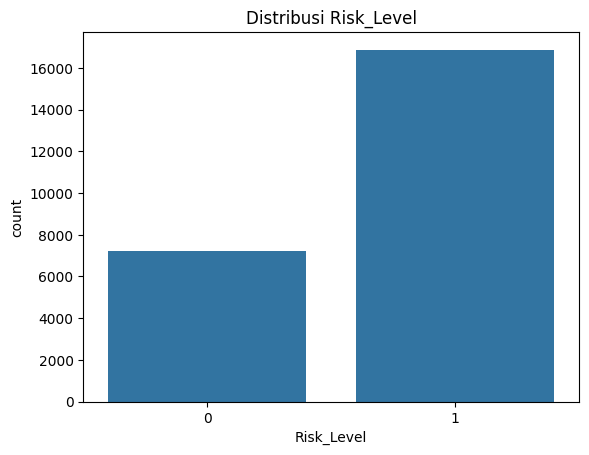

In [9]:
print(df_clean['Risk_Level'].value_counts(normalize=True).round(3))

sns.countplot(x=df_clean['Risk_Level'])
plt.title('Distribusi Risk_Level')
plt.show()

# Korelasi Fitur

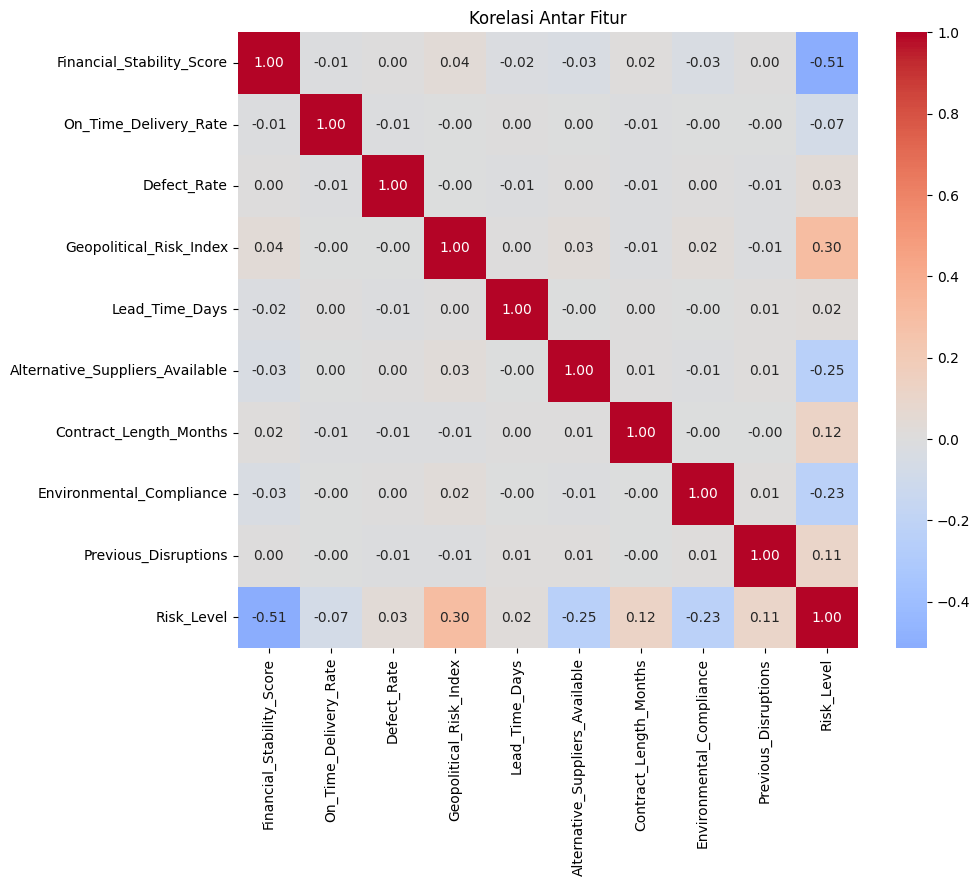

Financial_Stability_Score         -0.514246
Alternative_Suppliers_Available   -0.246206
Environmental_Compliance          -0.226029
On_Time_Delivery_Rate             -0.071603
Lead_Time_Days                     0.023022
Defect_Rate                        0.030909
Previous_Disruptions               0.110905
Contract_Length_Months             0.120097
Geopolitical_Risk_Index            0.301731
Name: Risk_Level, dtype: float64

In [10]:
corr = df_clean.drop(columns='Supplier_ID').corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Korelasi Antar Fitur')
plt.show()

corr['Risk_Level'].drop('Risk_Level').sort_values()

**Insight:**
- **Target tidak seimbang** (70% Risk_Level=1, 30% =0) → gunakan `stratify` saat split, metrik F1/ROC-AUC (bukan accuracy), dan `class_weight='balanced'`.
- Fitur paling berkorelasi dengan risiko: `Financial_Stability_Score` (−0.51), `Geopolitical_Risk_Index` (+0.30), `Alternative_Suppliers_Available` (−0.25), `Environmental_Compliance` (−0.23).
- `Lead_Time_Days` dan `Defect_Rate` hampir tidak berkorelasi linear (~0.02–0.03), tetapi **tidak dibuang dulu** — bisa jadi berpengaruh non-linear; dicek ulang lewat feature importance di tahap modeling.
- Korelasi antar fitur sangat rendah (maks 0.04) → tidak ada masalah multikolinearitas.

# Simpan Data Bersih

In [11]:
# Masih mengandung null value -> diimputasi di notebook 02 setelah split
os.makedirs('../data/processed', exist_ok=True)
df_clean.to_csv('../data/processed/supplier_clean.csv', index=False)